# Customer Segmentation using RFM Analysis

**Internship Project – Syntecxhub**

## Project Overview

This project aims to analyze customer purchasing
behavior using RFM (Recency, Frequency, Monetary)
analysis and group customers into meaningful
segments for targeted marketing strategies.

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:


dataset_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

df = pd.read_excel(dataset_url)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)


Dataset downloaded successfully!
Dataset shape: (541909, 8)


In [3]:


df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:


print("Dataset Columns:")

for column in df.columns:
    print(column)


Dataset Columns:
InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country


In [5]:


df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:


missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)


Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [7]:


missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))


Missing Value Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [8]:
missing_values = df.isnull().sum()
print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [10]:
duplicate_count = df.duplicated().sum()
print("Duplicate Records:", duplicate_count)

Duplicate Records: 5268


In [11]:
df = df.drop_duplicates()
print("Dataset Shape:", df.shape)

Dataset Shape: (536641, 8)


In [12]:
negative_quantity = (df['Quantity'] < 0).sum()
print("Negative Quantity Records:", negative_quantity)

Negative Quantity Records: 10587


In [13]:
invalid_price = (df['UnitPrice'] <= 0).sum()
print("Invalid UnitPrice Records:", invalid_price)

Invalid UnitPrice Records: 2512


In [14]:
df = df.dropna(subset=['CustomerID'])
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [15]:
df = df[df['Quantity'] > 0]
print(df.shape)

(392732, 8)


In [16]:
df = df[df['UnitPrice'] > 0]
print(df.shape)

(392692, 8)


In [17]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
print(df.shape)

(392692, 8)


In [18]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [19]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [20]:
analysis_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

print("Analysis Date:", analysis_date)

Analysis Date: 2011-12-10 12:50:00


In [21]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (analysis_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [22]:
print(rfm.shape)
print(rfm.describe())

(4338, 3)
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2048.688081
std     100.014169     7.697998    8985.230220
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     306.482500
50%      51.000000     2.000000     668.570000
75%     142.000000     5.000000    1660.597500
max     374.000000   209.000000  280206.020000


In [23]:
rfm.head(10)

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40
12352.0,36,8,2506.04
12353.0,204,1,89.00
12354.0,232,1,1079.40
12355.0,214,1,459.40


In [24]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [25]:
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

In [26]:
rfm['Total_Score'] = (
    rfm['R_Score'].astype(int) +
    rfm['F_Score'].astype(int) +
    rfm['M_Score'].astype(int)
)

In [27]:
rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Total_Score
CustomerID,,,,,,,,
12346.0,326,1,77183.60,1,1,5,115,7
12347.0,2,7,4310.00,5,5,5,555,15
12348.0,75,4,1797.24,2,4,4,244,10
12349.0,19,1,1757.55,4,1,4,414,9
12350.0,310,1,334.40,1,1,2,112,4
12352.0,36,8,2506.04,3,5,5,355,13
12353.0,204,1,89.00,1,1,1,111,3
12354.0,232,1,1079.40,1,1,4,114,6
12355.0,214,1,459.40,1,1,2,112,4


In [28]:
rfm[['R_Score', 'F_Score', 'M_Score']].describe()

,R_Score,F_Score,M_Score
count,4338,4338,4338
unique,5,5,5
top,5,1,1
freq,868,868,868


In [29]:
def segment_customer(row):

    if row['R_Score'] >= 4 and row['F_Score'] >= 4:
        return 'Loyal Customers'

    elif row['R_Score'] >= 4 and row['F_Score'] <= 2:
        return 'New Customers'

    elif row['R_Score'] <= 2 and row['F_Score'] >= 3:
        return 'At Risk Customers'

    elif row['R_Score'] <= 2 and row['F_Score'] <= 2:
        return 'Lost Customers'

    else:
        return 'Potential Loyal Customers'


rfm['Customer_Segment'] = rfm.apply(segment_customer, axis=1)

In [30]:
rfm[['Recency', 'Frequency', 'Monetary', 'RFM_Score', 'Customer_Segment']].head(10)

,Recency,Frequency,Monetary,RFM_Score,Customer_Segment
CustomerID,,,,,
12346.0,326,1,77183.60,115,Lost Customers
12347.0,2,7,4310.00,555,Loyal Customers
12348.0,75,4,1797.24,244,At Risk Customers
12349.0,19,1,1757.55,414,New Customers
12350.0,310,1,334.40,112,Lost Customers
12352.0,36,8,2506.04,355,Potential Loyal Customers
12353.0,204,1,89.00,111,Lost Customers
12354.0,232,1,1079.40,114,Lost Customers
12355.0,214,1,459.40,112,Lost Customers


In [31]:
segment_counts = rfm['Customer_Segment'].value_counts()

print(segment_counts)

Customer_Segment
Potential Loyal Customers    1172
Loyal Customers              1121
Lost Customers               1074
At Risk Customers             661
New Customers                 310
Name: count, dtype: int64


In [32]:
segment_percentage = (segment_counts / len(rfm)) * 100

print(segment_percentage.round(2))

Customer_Segment
Potential Loyal Customers    27.02
Loyal Customers              25.84
Lost Customers               24.76
At Risk Customers            15.24
New Customers                 7.15
Name: count, dtype: float64


In [33]:
segment_analysis = rfm.groupby('Customer_Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

print(segment_analysis)

                           Recency  Frequency  Monetary
Customer_Segment                                       
At Risk Customers           150.64       3.41   1246.46
Lost Customers              216.68       1.10    487.71
Loyal Customers              13.00      10.05   5225.51
New Customers                18.10       1.25    458.84
Potential Loyal Customers    41.78       2.93   1313.53


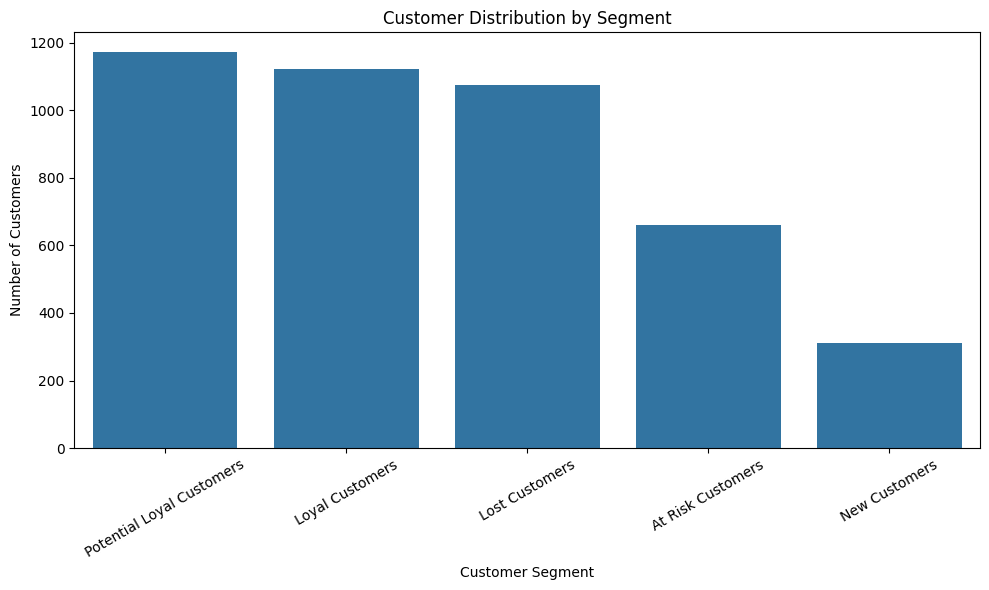

In [34]:
plt.figure(figsize=(10, 6))

sns.countplot(data=rfm, x='Customer_Segment', order=rfm['Customer_Segment'].value_counts().index)

plt.title('Customer Distribution by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

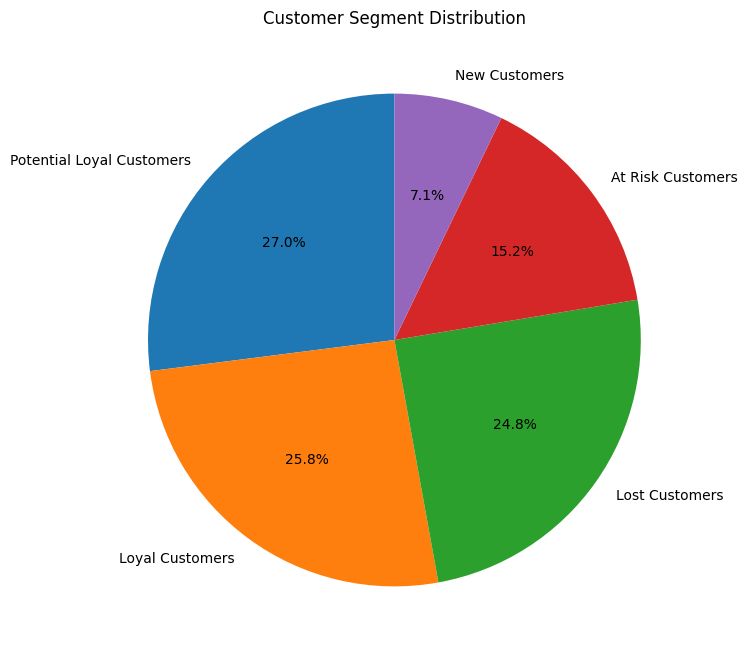

In [35]:
plt.figure(figsize=(8, 8))

plt.pie(segment_counts, labels=segment_counts.index, autopct='%1.1f%%', startangle=90)

plt.title('Customer Segment Distribution')
plt.show()

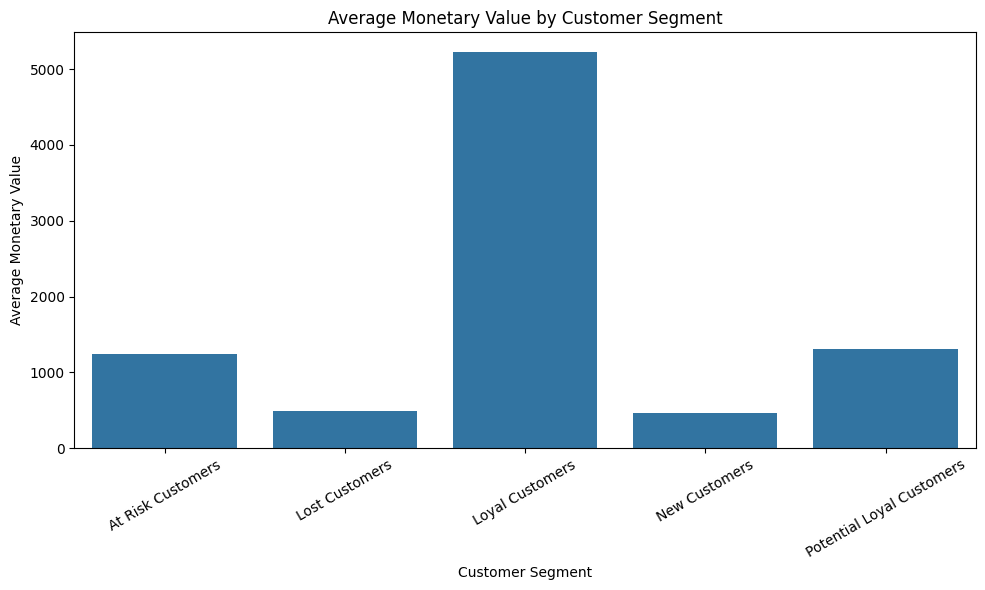

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(x=segment_analysis.index, y=segment_analysis['Monetary'])

plt.title('Average Monetary Value by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Monetary Value')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

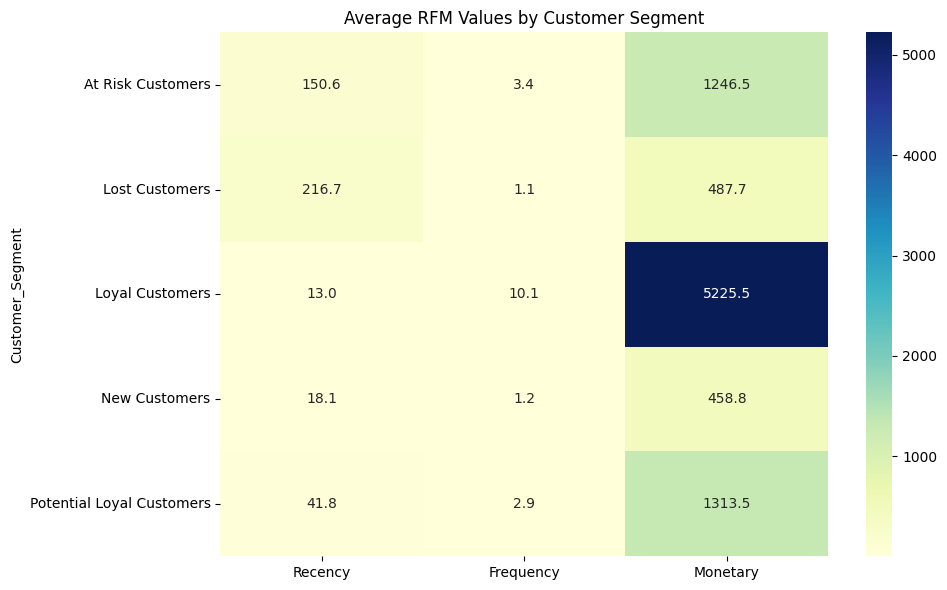

In [37]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    rfm.groupby('Customer_Segment')[['Recency', 'Frequency', 'Monetary']].mean(),
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Average RFM Values by Customer Segment')
plt.tight_layout()
plt.show()

In [38]:
final_results = rfm[['Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Total_Score', 'Customer_Segment']]

final_results.to_csv('Customer_Segmentation_Results.csv')

final_results.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Total_Score,Customer_Segment
CustomerID,,,,,,,,,
12346.0,326,1,77183.60,1,1,5,115,7,Lost Customers
12347.0,2,7,4310.00,5,5,5,555,15,Loyal Customers
12348.0,75,4,1797.24,2,4,4,244,10,At Risk Customers
12349.0,19,1,1757.55,4,1,4,414,9,New Customers
12350.0,310,1,334.40,1,1,2,112,4,Lost Customers
12352.0,36,8,2506.04,3,5,5,355,13,Potential Loyal Customers
12353.0,204,1,89.00,1,1,1,111,3,Lost Customers
12354.0,232,1,1079.40,1,1,4,114,6,Lost Customers
12355.0,214,1,459.40,1,1,2,112,4,Lost Customers


In [39]:
from google.colab import files

files.download('Customer_Segmentation_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
segment_summary = rfm.groupby('Customer_Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).round(2)

segment_summary['Customer_Count'] = rfm.groupby('Customer_Segment').size()

segment_summary.to_csv('Customer_Segment_Summary.csv')

segment_summary

,Recency,Frequency,Monetary,Customer_Count
Customer_Segment,,,,
At Risk Customers,150.64,3.41,1246.46,661
Lost Customers,216.68,1.10,487.71,1074
Loyal Customers,13.00,10.05,5225.51,1121
New Customers,18.10,1.25,458.84,310
Potential Loyal Customers,41.78,2.93,1313.53,1172


In [43]:
from google.colab import files

files.download('Customer_Segment_Summary.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
business_recommendations = pd.DataFrame({
    'Customer_Segment': [
        'Loyal Customers',
        'Potential Loyal Customers',
        'At Risk Customers',
        'Lost Customers',
        'New Customers'
    ],
    'Business_Strategy': [
        'VIP Rewards and Loyalty Points',
        'Personalized Promotions',
        'Re-engagement Campaigns',
        'Win-back Offers',
        'Welcome Offers'
    ]
})

business_recommendations

,Customer_Segment,Business_Strategy
0,Loyal Customers,VIP Rewards and Loyalty Points
1,Potential Loyal Customers,Personalized Promotions
2,At Risk Customers,Re-engagement Campaigns
3,Lost Customers,Win-back Offers
4,New Customers,Welcome Offers


In [50]:
readme_content = """# Customer Segmentation Using RFM Analysis

## Project Overview

This project focuses on customer segmentation using RFM (Recency, Frequency, Monetary) Analysis.

## Objectives

- Analyze customer purchasing behaviour.
- Calculate RFM values.
- Identify different customer segments.
- Visualize customer distribution.
- Provide business recommendations.

## Dataset

Online Retail Dataset from UCI Machine Learning Repository.

## Technologies Used

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Customer Segments

- Loyal Customers
- Potential Loyal Customers
- At Risk Customers
- Lost Customers
- New Customers

## Results

The analysis identified 4,338 customers across five customer segments.

## Conclusion

RFM analysis helps businesses understand customer purchasing behaviour, improve customer retention, and develop targeted marketing strategies.
"""

with open('/content/README.md', 'w') as file:
    file.write(readme_content)

In [51]:
from google.colab import files

files.download('/content/README.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
!pip install python-docx

In [48]:
from docx import Document

doc = Document()

doc.add_heading('Customer Segmentation Using RFM Analysis', 0)

doc.add_heading('1. Introduction', level=1)
doc.add_paragraph(
    'This project focuses on customer segmentation using RFM analysis. '
    'RFM stands for Recency, Frequency, and Monetary.'
)

doc.add_heading('2. Project Objectives', level=1)
doc.add_paragraph('Analyze customer purchasing behaviour.')
doc.add_paragraph('Identify different customer segments.')
doc.add_paragraph('Improve customer retention using data-driven insights.')

doc.add_heading('3. Dataset Description', level=1)
doc.add_paragraph(
    'The Online Retail dataset was obtained from the UCI Machine Learning Repository. '
    'It contains transaction details such as InvoiceNo, Quantity, InvoiceDate, '
    'UnitPrice, CustomerID, and Country.'
)

doc.add_heading('4. Technologies Used', level=1)
doc.add_paragraph('Python, Google Colab, Pandas, NumPy, Matplotlib, and Seaborn.')

doc.add_heading('5. Data Cleaning', level=1)
doc.add_paragraph(
    'Missing CustomerID values, duplicate records, negative quantities, '
    'invalid prices, and cancelled transactions were handled.'
)

doc.add_heading('6. RFM Analysis', level=1)
doc.add_paragraph(
    'Recency measures how recently a customer purchased. '
    'Frequency measures how often a customer purchased. '
    'Monetary measures the total amount spent by a customer.'
)

doc.add_heading('7. Customer Segmentation Results', level=1)

for segment, count in rfm['Customer_Segment'].value_counts().items():
    doc.add_paragraph(f'{segment}: {count} customers')

doc.add_heading('8. Business Recommendations', level=1)
doc.add_paragraph('Loyal Customers: Provide loyalty rewards.')
doc.add_paragraph('Potential Loyal Customers: Offer personalized promotions.')
doc.add_paragraph('At Risk Customers: Use re-engagement campaigns.')
doc.add_paragraph('Lost Customers: Provide win-back offers.')
doc.add_paragraph('New Customers: Provide welcome offers.')

doc.add_heading('9. Conclusion', level=1)
doc.add_paragraph(
    'The project identified 4,338 customers across five segments. '
    'RFM analysis provides useful insights into customer purchasing behaviour '
    'and helps businesses develop targeted marketing strategies.'
)

doc.save('/content/Customer_Segmentation_Report.docx')

In [49]:
files.download('/content/Customer_Segmentation_Report.docx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
plt.savefig('/content/customer_distribution.png', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [53]:
plt.savefig('/content/customer_pie_chart.png', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [54]:
plt.savefig('/content/monetary_analysis.png', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [57]:
import os

print(os.listdir('/content'))

['.config', 'monetary_analysis.png', 'Customer_Segment_Summary.csv', 'Customer_Segmentation_Results.csv', 'README.md', 'Customer_Segmentation_Report.docx', 'customer_pie_chart.png', 'customer_distribution.png', 'sample_data']


In [58]:
import os

for file in os.listdir('/content'):
    if file.endswith('.png'):
        print(file)

monetary_analysis.png
customer_pie_chart.png
customer_distribution.png


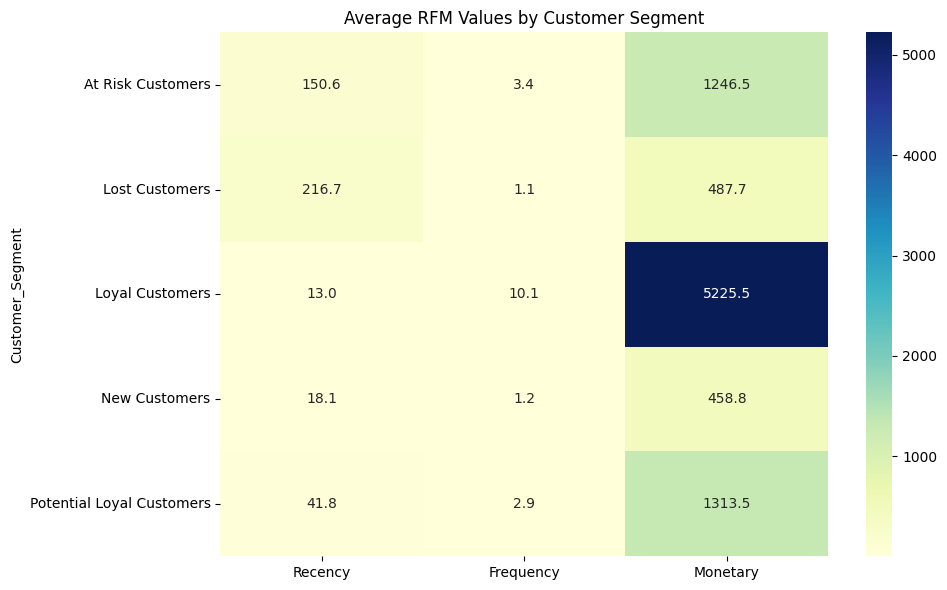

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.heatmap(
    rfm.groupby('Customer_Segment')[['Recency', 'Frequency', 'Monetary']].mean(),
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Average RFM Values by Customer Segment')
plt.tight_layout()
plt.savefig('/content/rfm_heatmap.png', bbox_inches='tight')
plt.show()

In [60]:
from docx import Document
from docx.shared import Inches

doc = Document('/content/Customer_Segmentation_Report.docx')

doc.add_heading('10. Data Visualization', level=1)

graphs = [
    ('Customer Distribution by Segment', '/content/customer_distribution.png'),
    ('Customer Segment Distribution', '/content/customer_pie_chart.png'),
    ('Average Monetary Value by Segment', '/content/monetary_analysis.png'),
    ('Average RFM Values by Segment', '/content/rfm_heatmap.png')
]

for title, image_path in graphs:
    doc.add_heading(title, level=2)
    doc.add_picture(image_path, width=Inches(5.5))

doc.save('/content/Customer_Segmentation_Final_Report.docx')

In [61]:
from google.colab import files

files.download('/content/Customer_Segmentation_Final_Report.docx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>